# Tarefa 4 – Desenvolvimento e testes de um protótipo baseado em IA Generativa com Engenharia de Prompts

**Módulo 4:** IA Generativa e Interação com os Modelos de Linguagem

## Caso de uso: assistente de estudo (perguntas e respostas sobre um documento)

O protótipo responde a perguntas sobre um excerto do material do curso: as secções 3.2 e 3.3 da UD3 (ciclo de vida de um sistema generativo e LLMOps). Usa a API do Google Gemini e compara três versões de prompt sobre as mesmas quatro perguntas. Uma das perguntas não tem resposta no excerto, para ver se o modelo admite que não sabe ou se inventa.

### Considerações a ter em conta
- A chave de API lê-se da variável de ambiente `GEMINI_API_KEY`. Nunca está escrita no código.
- Os ficheiros `excerto_UD3_LLMOps.txt` e `figura_4_ciclo_de_vida.png` têm de estar na mesma pasta do notebook.
- Bibliotecas: `google-genai`, `pandas` e `matplotlib`.
- Na Parte 4, a clareza e a relevância de cada resposta são avaliadas manualmente (notas de 1 a 5), por quem executa o notebook.
- O notebook gera ficheiros de registo na mesma pasta: `registo_interacoes_T4.csv`, `registo_tentativas_T4.csv`, `versoes_prompts_T4.json` e `grafico_comparacao_prompts_T4.png`.

## Parte 1 – Implementação com modelo de linguagem

Usa-se a API do Google Gemini com a biblioteca oficial `google-genai`. O modelo usado é o `gemini-3.5-flash`. O `gemini-3.8-flash`, mais recente, foi testado primeiro, mas devolveu repetidamente o erro 503 (serviço sobrecarregado) durante o desenvolvimento, pelo que se optou pelo 3.5. O pedido é feito com o nome `gemini-3.5-flash`; a API indica, em cada resposta, o modelo efetivo, que fica registado na coluna `modelo_devolvido`. A temperatura não é alterada: segue-se a recomendação da Google de manter o valor por defeito nos modelos Gemini 3.

In [1]:
# Importa o módulo os, para ler a variável de ambiente onde está guardada a chave
import os

# Importa o módulo time, para medir tempos de resposta e fazer pausas entre tentativas
import time

# Importa o módulo json, para guardar as versões dos prompts num ficheiro
import json

# Importa o módulo textwrap, para quebrar os nomes compridos nas legendas do gráfico
import textwrap

# Importa a classe datetime, para registar a data e a hora de cada interação
from datetime import datetime

# Importa o pandas, com o alias habitual pd, para organizar os registos em tabelas
import pandas as pd

# Importa o matplotlib, com o alias habitual plt, para o gráfico de comparação
import matplotlib.pyplot as plt

# Importa o cliente da biblioteca oficial da Google para a API Gemini
from google import genai

# Importa os tipos da biblioteca (tempo limite, imagens), com um alias curto
from google.genai import types as tipos_gemini

# Importa os erros da API, para distinguir falhas temporárias de falhas definitivas
from google.genai import errors as erros_gemini

In [2]:
# Modelo usado em todos os pedidos (escolhido a partir da lista de modelos disponíveis na conta)
nome_modelo_em_uso = "gemini-3.5-flash"

# Temperatura: não é definida no código, por isso o modelo usa o valor por defeito
descricao_temperatura = "por defeito do modelo"

# Número máximo de tentativas por pedido (a primeira conta como tentativa)
numero_maximo_tentativas = 3

# Espera antes da segunda tentativa, em segundos. Duplica a cada nova falha (5 s, depois 10 s)
segundos_espera_inicial = 5

# Tempo máximo de espera por cada pedido, em segundos
limite_tempo_segundos = 60

# Pausa entre pedidos consecutivos, em segundos. Mantém o ritmo abaixo do limite de pedidos por minuto da conta (erro 429)
segundos_pausa_entre_pedidos = 12

# Códigos de erro que são temporários e justificam nova tentativa (429: limite de pedidos; 5xx: servidor)
codigos_erro_temporarios = (429, 500, 503, 504)

# Nomes dos ficheiros de registo, guardados na mesma pasta do notebook
ficheiro_registo_interacoes = "registo_interacoes_T4.csv"
ficheiro_registo_tentativas = "registo_tentativas_T4.csv"
ficheiro_versoes_prompts = "versoes_prompts_T4.json"
ficheiro_grafico = "grafico_comparacao_prompts_T4.png"

### Verificar a chave e criar o cliente

A célula seguinte só confirma que a variável existe. Nunca mostra o valor da chave.

In [3]:
# Lê a chave de API da variável de ambiente GEMINI_API_KEY (devolve None se não existir)
chave_api = os.environ.get("GEMINI_API_KEY")

# Considera a chave definida apenas se existir e não estiver vazia
chave_definida = chave_api is not None and chave_api.strip() != ""

# Informa o resultado sem nunca mostrar o valor da chave
if chave_definida:
    print("A variável de ambiente GEMINI_API_KEY está definida.")
else:
    print("A variável de ambiente GEMINI_API_KEY não está definida.")
    print("É necessário defini-la e reiniciar o ambiente (por exemplo, fechar e voltar a abrir o VS Code) antes de executar de novo.")

# Define o tempo limite e desativa as repetições automáticas da biblioteca (attempts=1).
# As novas tentativas passam a ser feitas, e registadas, pela função pedir_ao_modelo
opcoes_http = tipos_gemini.HttpOptions(
    timeout=limite_tempo_segundos * 1000,
    retry_options=tipos_gemini.HttpRetryOptions(attempts=1),
)

# Cria o cliente, que lê a chave da variável de ambiente
cliente_gemini = genai.Client(http_options=opcoes_http) if chave_definida else None
print(f"Cliente criado: {cliente_gemini is not None}")

A variável de ambiente GEMINI_API_KEY está definida.
Cliente criado: True


### Funções de apoio (Parte 4: registo das operações)

- `pedir_ao_modelo` envia um pedido, repete-o se a falha for temporária e regista cada tentativa.
- `guardar_interacao` acrescenta uma linha ao registo das interações, com o modelo, a versão do prompt, o tempo e a resposta. Se o mesmo pedido já constar no registo (por ter falhado antes), a linha antiga é substituída.

In [4]:
# Listas onde se vão guardando as interações e as tentativas
registo_interacoes = []
registo_tentativas = []


def pedir_ao_modelo(conteudo, versao_prompt, numero_pergunta):
    """Envia um pedido ao modelo, repete em falhas temporárias e regista cada tentativa.
    Devolve um dicionário com o estado, a resposta, o número de tentativas e os tempos."""
    resultado = {
        "estado": "erro",
        "resposta": "",
        "modelo_devolvido": "",
        "tentativas": 0,
        "tempo_resposta_segundos": None,
        "tempo_total_segundos": None,
        "erro": "",
    }

    # Sem cliente (chave em falta) não há nada a enviar
    if cliente_gemini is None:
        resultado["erro"] = "Sem cliente: a chave de API não está definida."
        return resultado

    instante_inicio_total = time.perf_counter()
    espera_atual_segundos = segundos_espera_inicial

    for numero_tentativa in range(1, numero_maximo_tentativas + 1):
        resultado["tentativas"] = numero_tentativa
        instante_inicio_tentativa = time.perf_counter()

        try:
            resposta_modelo = cliente_gemini.models.generate_content(
                model=nome_modelo_em_uso,
                contents=conteudo,
            )
            tempo_tentativa = time.perf_counter() - instante_inicio_tentativa
            texto_resposta = resposta_modelo.text or ""
            estado_tentativa = "sucesso" if texto_resposta.strip() != "" else "sem texto"

            registo_tentativas.append({
                "data_hora": datetime.now().isoformat(timespec="seconds"),
                "modelo": nome_modelo_em_uso,
                "versao_prompt": versao_prompt,
                "numero_pergunta": numero_pergunta,
                "numero_tentativa": numero_tentativa,
                "resultado": estado_tentativa,
                "codigo_erro": "",
                "tipo_erro": "",
                "tempo_segundos": round(tempo_tentativa, 2),
            })

            resultado["estado"] = estado_tentativa
            resultado["resposta"] = texto_resposta.strip()
            # Versão exata do modelo que respondeu, indicada pela própria API (pode diferir do nome pedido)
            resultado["modelo_devolvido"] = str(getattr(resposta_modelo, "model_version", "") or "")
            resultado["tempo_resposta_segundos"] = round(tempo_tentativa, 2)
            resultado["erro"] = ""
            break

        except Exception as erro:
            tempo_tentativa = time.perf_counter() - instante_inicio_tentativa
            codigo_erro = getattr(erro, "code", "")

            # Falhas de ligação ou de tempo limite não trazem código; tratam-se como temporárias
            erro_temporario = (codigo_erro in codigos_erro_temporarios) or (not isinstance(erro, erros_gemini.APIError))

            registo_tentativas.append({
                "data_hora": datetime.now().isoformat(timespec="seconds"),
                "modelo": nome_modelo_em_uso,
                "versao_prompt": versao_prompt,
                "numero_pergunta": numero_pergunta,
                "numero_tentativa": numero_tentativa,
                "resultado": "erro",
                "codigo_erro": codigo_erro,
                "tipo_erro": type(erro).__name__,
                "tempo_segundos": round(tempo_tentativa, 2),
            })
            resultado["erro"] = f"{type(erro).__name__} {codigo_erro}".strip()

            if erro_temporario and numero_tentativa < numero_maximo_tentativas:
                print(f"   Falha temporária ({resultado['erro']}). Nova tentativa dentro de {espera_atual_segundos} segundos...")
                time.sleep(espera_atual_segundos)
                espera_atual_segundos = espera_atual_segundos * 2
            else:
                break

    resultado["tempo_total_segundos"] = round(time.perf_counter() - instante_inicio_total, 2)
    return resultado


def guardar_interacao(versao_prompt, numero_pergunta, pergunta, resposta_esperada, resultado):
    """Acrescenta ao registo das interações uma linha com tudo o que interessa avaliar depois.
    Se o mesmo pedido já existir (uma falha repetida), a linha antiga é substituída pela nova."""
    registo_interacoes[:] = [
        linha for linha in registo_interacoes
        if not (linha["versao_prompt"] == versao_prompt and linha["numero_pergunta"] == numero_pergunta)
    ]
    registo_interacoes.append({
        "data_hora": datetime.now().isoformat(timespec="seconds"),
        "modelo": nome_modelo_em_uso,
        "modelo_devolvido": resultado["modelo_devolvido"],
        "temperatura": descricao_temperatura,
        "versao_prompt": versao_prompt,
        "numero_pergunta": numero_pergunta,
        "pergunta": pergunta,
        "resposta_esperada": resposta_esperada,
        "estado": resultado["estado"],
        "tentativas": resultado["tentativas"],
        "tempo_resposta_segundos": resultado["tempo_resposta_segundos"],
        "tempo_total_segundos": resultado["tempo_total_segundos"],
        "numero_palavras": len(resultado["resposta"].split()),
        "resposta": resultado["resposta"],
        "erro": resultado["erro"],
        "clareza": None,
        "relevancia": None,
        "inventou_resposta": "",
    })
    # Guarda o registo completo em CSV a cada interação, para não perder nada se o notebook parar
    pd.DataFrame(registo_interacoes).to_csv(ficheiro_registo_interacoes, index=False, encoding="utf-8-sig")

### Teste inicial

Uma pergunta simples, só para validar que o ambiente e a ligação ao modelo funcionam.

In [5]:
# Pergunta simples, só para validar a ligação ao modelo
pergunta_teste = "Responde numa frase, em português europeu: o que é um grande modelo de linguagem?"

# Envia o pedido com a função que repete em falhas temporárias
resultado_teste = pedir_ao_modelo(pergunta_teste, "Teste inicial", 0)

print(f"Modelo usado: {nome_modelo_em_uso}")
print(f"Pergunta enviada: {pergunta_teste}")
print(f"Estado: {resultado_teste['estado']} (tentativas: {resultado_teste['tentativas']})")

if resultado_teste["estado"] == "sucesso":
    print(f"Resposta do modelo: {resultado_teste['resposta']}")
    print(f"Tempo de resposta: {resultado_teste['tempo_resposta_segundos']:.2f} segundos")
    print(f"Modelo indicado pela API: {resultado_teste['modelo_devolvido'] or 'não indicado'}")
else:
    print(f"O teste inicial falhou: {resultado_teste['erro']}")
    # Interrompe a execução para não enviar os restantes pedidos nem gastar a quota da conta
    raise RuntimeError("Teste inicial sem sucesso: execução interrompida. Resolver a causa do erro e executar de novo.")

Modelo usado: gemini-3.5-flash
Pergunta enviada: Responde numa frase, em português europeu: o que é um grande modelo de linguagem?
Estado: sucesso (tentativas: 1)
Resposta do modelo: Um grande modelo de linguagem é um sistema de inteligência artificial treinado com vastos volumes de texto para compreender, processar e gerar linguagem humana de forma natural.
Tempo de resposta: 3.75 segundos
Modelo indicado pela API: gemini-3.6-flash


## Parte 2 – Engenharia de prompts

Três versões de prompt para o mesmo objetivo (responder a perguntas sobre o excerto), cada uma com mais técnicas do que a anterior:

| Prompt | Técnicas |
|---|---|
| Prompt 1 (básico) | Zero-shot: uma instrução simples, sem exemplos |
| Prompt 2 (contexto e passos) | Atribuição de papel, delimitação do contexto, instruções passo a passo e regras de resposta |
| Prompt 3 (com exemplos) | O Prompt 2 mais dois exemplos (few-shot), um com resposta no texto e outro sem |

Os três usam o mesmo modelo e as mesmas quatro perguntas, para a diferença nas respostas poder ser atribuída ao prompt.

In [6]:
# Nomes dos ficheiros de entrada (têm de estar na mesma pasta do notebook)
ficheiro_excerto = "excerto_UD3_LLMOps.txt"
ficheiro_figura = "figura_4_ciclo_de_vida.png"

# Confirma que os ficheiros existem antes de continuar
if not os.path.exists(ficheiro_excerto) or not os.path.exists(ficheiro_figura):
    raise FileNotFoundError(
        f"Ficheiros em falta: {ficheiro_excerto} e {ficheiro_figura} têm de estar na mesma pasta do notebook."
    )

# Lê o excerto do curso, que serve de documento para as perguntas
with open(ficheiro_excerto, "r", encoding="utf-8") as ficheiro_aberto:
    texto_excerto = ficheiro_aberto.read()

print(f"Excerto carregado: {len(texto_excerto)} caracteres.")
print(f"Início do excerto: {texto_excerto[:90]}...")

Excerto carregado: 1439 caracteres.
Início do excerto: 3.2 Ciclo de vida de um sistema generativo

O desenvolvimento de um sistema de IA generati...


In [7]:
# As quatro perguntas fixas, com a resposta esperada (retirada do excerto) como referência para a avaliação
# As perguntas 1 a 3 têm resposta no excerto. A pergunta 4 não tem, para testar se o modelo inventa
perguntas = [
    {
        "numero": 1,
        "pergunta": "Quais são as etapas do ciclo de vida de um sistema generativo?",
        "resposta_esperada": "As 6 etapas da tabela: seleção do modelo, preparação dos dados, afinamento (fine-tuning), integração em sistemas, monitorização e atualização.",
    },
    {
        "numero": 2,
        "pergunta": "O que é o LLMOps e qual é o seu foco?",
        "resposta_esperada": "Subconjunto do MLOps adaptado aos LLMs, focado na operacionalização estável, segura e escalável em ambientes de produção.",
    },
    {
        "numero": 3,
        "pergunta": "Qual é a diferença entre fine-tuning e inference?",
        "resposta_esperada": "Fine-tuning é continuar o treino do modelo com dados especializados. Inference é a fase em que o modelo gera respostas depois de treinado.",
    },
    {
        "numero": 4,
        "pergunta": "Qual é o custo mensal médio de uma plataforma de LLMOps numa empresa?",
        "resposta_esperada": "O excerto não diz. O modelo deve admitir que não consta, em vez de inventar um valor.",
    },
]

print(f"Número de perguntas: {len(perguntas)}")
for pergunta_atual in perguntas:
    print(f"{pergunta_atual['numero']}. {pergunta_atual['pergunta']}")

Número de perguntas: 4
1. Quais são as etapas do ciclo de vida de um sistema generativo?
2. O que é o LLMOps e qual é o seu foco?
3. Qual é a diferença entre fine-tuning e inference?
4. Qual é o custo mensal médio de uma plataforma de LLMOps numa empresa?


In [8]:
# Prompt 1 (básico, zero-shot): só uma instrução simples
modelo_prompt_1 = """Responde à pergunta com base no texto.

{excerto}

Pergunta: {pergunta}"""

# Instruções do Prompt 2: papel, delimitação do contexto, passos e regras de resposta
instrucoes_prompt_2 = """Atua como assistente de estudo de um curso de Inteligência Artificial.
O texto de referência está entre as etiquetas <excerto> e </excerto>.

Segue estes passos:
1. Lê o excerto com atenção.
2. Procura nele a informação relevante para a pergunta.
3. Responde só com o que está no excerto, em português europeu, em no máximo 3 frases.
4. Se a resposta não estiver no excerto, responde exatamente: "Esta informação não consta no excerto."
"""

# Fim comum aos Prompts 2 e 3: o excerto delimitado e a pergunta
fim_prompt_com_excerto = """
<excerto>
{excerto}
</excerto>

Pergunta: {pergunta}"""

# Prompt 2: as instruções seguidas do excerto e da pergunta
modelo_prompt_2 = instrucoes_prompt_2 + fim_prompt_com_excerto

# Exemplos do Prompt 3 (few-shot), de outro tema para não se confundirem com o excerto
exemplos_prompt_3 = """
Exemplo 1
<excerto>A Biblioteca Municipal abre de segunda a sexta, das 9h às 18h.</excerto>
Pergunta: A que horas abre a biblioteca?
Resposta: Abre às 9h.

Exemplo 2
<excerto>A Biblioteca Municipal abre de segunda a sexta, das 9h às 18h.</excerto>
Pergunta: Quanto custa a inscrição?
Resposta: Esta informação não consta no excerto.
"""

# Prompt 3: as instruções do Prompt 2, os exemplos, o excerto e a pergunta
modelo_prompt_3 = instrucoes_prompt_2 + exemplos_prompt_3 + fim_prompt_com_excerto + "\nResposta:"

# Reúne as três versões, com as técnicas usadas em cada uma
prompts_a_testar = [
    {"nome": "Prompt 1 (básico)", "tecnicas": "zero-shot", "modelo": modelo_prompt_1},
    {"nome": "Prompt 2 (contexto e passos)", "tecnicas": "papel, delimitação do contexto, passos, regras de resposta", "modelo": modelo_prompt_2},
    {"nome": "Prompt 3 (com exemplos)", "tecnicas": "tudo do Prompt 2 e dois exemplos (few-shot)", "modelo": modelo_prompt_3},
]

# Guarda as versões dos prompts num ficheiro (Parte 4: registo das versões)
with open(ficheiro_versoes_prompts, "w", encoding="utf-8") as ficheiro_aberto:
    json.dump(prompts_a_testar, ficheiro_aberto, ensure_ascii=False, indent=2)

for prompt_atual in prompts_a_testar:
    print(f"{prompt_atual['nome']}: {prompt_atual['tecnicas']}")
print(f"Versões dos prompts guardadas em {ficheiro_versoes_prompts}.")

Prompt 1 (básico): zero-shot
Prompt 2 (contexto e passos): papel, delimitação do contexto, passos, regras de resposta
Prompt 3 (com exemplos): tudo do Prompt 2 e dois exemplos (few-shot)
Versões dos prompts guardadas em versoes_prompts_T4.json.


### Execução: 3 prompts × 4 perguntas = 12 pedidos

Cada pedido usa a função `pedir_ao_modelo`, por isso as falhas temporárias (como os erros 503 e 429) são repetidas, até 3 tentativas, e ficam registadas. Entre pedidos há uma pausa de 12 segundos, para respeitar o limite de pedidos por minuto da conta. Pode demorar alguns minutos.

**Repetição de pedidos falhados.** A comparação entre prompts só é justa se cada um tiver as mesmas 4 perguntas respondidas. Por isso, ao executar a célula de novo, os pedidos que já tiveram sucesso são saltados e apenas os que falharam são repetidos; o contador indica quando um pedido é saltado ou repetido. Os registos estão em memória durante a sessão, pelo que esta repetição funciona dentro da mesma sessão do notebook: depois de reiniciar o ambiente, os 12 pedidos voltam a ser feitos de raiz. Todas as tentativas, incluindo as falhadas, ficam registadas em `registo_tentativas_T4.csv`.

In [9]:
# Total de pedidos desta execução
total_pedidos = len(prompts_a_testar) * len(perguntas)
contador_pedidos = 0

# Percorre cada prompt e, dentro dele, cada pergunta
for prompt_atual in prompts_a_testar:
    for pergunta_atual in perguntas:
        contador_pedidos += 1

        # Procura se este pedido já foi feito numa execução anterior
        pedido_anterior = [
            linha for linha in registo_interacoes
            if linha["versao_prompt"] == prompt_atual["nome"] and linha["numero_pergunta"] == pergunta_atual["numero"]
        ]
        if pedido_anterior and pedido_anterior[0]["estado"] == "sucesso":
            print(f"Pedido {contador_pedidos} de {total_pedidos}: {prompt_atual['nome']}, pergunta {pergunta_atual['numero']} (já concluído, saltado)")
            continue
        if pedido_anterior:
            print(f"Pedido {contador_pedidos} de {total_pedidos}: repetição de um pedido que tinha falhado")

        # Preenche o modelo de prompt com o excerto e com a pergunta
        texto_pedido = prompt_atual["modelo"].format(
            excerto=texto_excerto,
            pergunta=pergunta_atual["pergunta"],
        )

        print(f"Pedido {contador_pedidos} de {total_pedidos}: {prompt_atual['nome']}, pergunta {pergunta_atual['numero']}")

        resultado_pedido = pedir_ao_modelo(texto_pedido, prompt_atual["nome"], pergunta_atual["numero"])

        guardar_interacao(
            prompt_atual["nome"],
            pergunta_atual["numero"],
            pergunta_atual["pergunta"],
            pergunta_atual["resposta_esperada"],
            resultado_pedido,
        )

        if resultado_pedido["estado"] == "sucesso":
            print(f"   Estado: sucesso | tentativas: {resultado_pedido['tentativas']} | tempo de resposta: {resultado_pedido['tempo_resposta_segundos']} s")
        else:
            print(f"   Estado: {resultado_pedido['estado']} | tentativas: {resultado_pedido['tentativas']} | erro: {resultado_pedido['erro']}")

        # Pausa antes do pedido seguinte, para não ultrapassar o limite de pedidos por minuto
        time.sleep(segundos_pausa_entre_pedidos)

print("Execução concluída.")

Pedido 1 de 12: Prompt 1 (básico), pergunta 1
   Estado: sucesso | tentativas: 1 | tempo de resposta: 2.4 s
Pedido 2 de 12: Prompt 1 (básico), pergunta 2
   Estado: sucesso | tentativas: 1 | tempo de resposta: 3.16 s
Pedido 3 de 12: Prompt 1 (básico), pergunta 3
   Estado: sucesso | tentativas: 1 | tempo de resposta: 4.46 s
Pedido 4 de 12: Prompt 1 (básico), pergunta 4
   Estado: sucesso | tentativas: 1 | tempo de resposta: 3.22 s
Pedido 5 de 12: Prompt 2 (contexto e passos), pergunta 1
   Estado: sucesso | tentativas: 1 | tempo de resposta: 2.86 s
Pedido 6 de 12: Prompt 2 (contexto e passos), pergunta 2
   Estado: sucesso | tentativas: 1 | tempo de resposta: 4.56 s
Pedido 7 de 12: Prompt 2 (contexto e passos), pergunta 3
   Estado: sucesso | tentativas: 1 | tempo de resposta: 4.24 s
Pedido 8 de 12: Prompt 2 (contexto e passos), pergunta 4
   Estado: sucesso | tentativas: 1 | tempo de resposta: 3.75 s
Pedido 9 de 12: Prompt 3 (com exemplos), pergunta 1
   Estado: sucesso | tentativas: 

## Parte 3 – Integração multimodal

Entrada de texto e imagem no mesmo pedido: o modelo recebe a Figura 4 do curso e o excerto, descreve a figura e compara as etapas que ela mostra com as da tabela. A resposta esperada é que a figura mostra 4 etapas e a tabela tem 6, por isso não coincidem totalmente.

In [10]:
# Lê a imagem em bytes, que é o formato que a API aceita para entradas multimodais
with open(ficheiro_figura, "rb") as ficheiro_imagem:
    bytes_figura = ficheiro_imagem.read()

# Cria a parte do pedido que contém a imagem
parte_imagem = tipos_gemini.Part.from_bytes(data=bytes_figura, mime_type="image/png")

# Texto do pedido multimodal (mesmo estilo do Prompt 2: papel, contexto delimitado e passos)
modelo_pedido_multimodal = """Atua como assistente de estudo de um curso de Inteligência Artificial.
Em anexo tens uma figura do material do curso. O texto de referência está entre as etiquetas <excerto> e </excerto>.

Segue estes passos:
1. Descreve a figura em português europeu, em no máximo 3 frases.
2. Indica quantas etapas a figura mostra.
3. Compara essas etapas com as da tabela do excerto e diz se coincidem.
Se a figura não mostrar algo, não inventes.

<excerto>
{excerto}
</excerto>"""

texto_pedido_multimodal = modelo_pedido_multimodal.format(excerto=texto_excerto)

# O conteúdo do pedido junta a imagem e o texto
conteudo_multimodal = [parte_imagem, texto_pedido_multimodal]

pergunta_multimodal = "Descreve a figura, indica quantas etapas mostra e compara-as com as da tabela do excerto."
resposta_esperada_multimodal = "A figura mostra 4 etapas e a tabela tem 6, por isso não coincidem totalmente."

resultado_multimodal = pedir_ao_modelo(conteudo_multimodal, "Multimodal (texto + imagem)", 5)

guardar_interacao(
    "Multimodal (texto + imagem)",
    5,
    pergunta_multimodal,
    resposta_esperada_multimodal,
    resultado_multimodal,
)

print(f"Estado: {resultado_multimodal['estado']} | tentativas: {resultado_multimodal['tentativas']}")
if resultado_multimodal["estado"] == "sucesso":
    print(f"Resposta do modelo:\n{resultado_multimodal['resposta']}")
    print(f"Tempo de resposta: {resultado_multimodal['tempo_resposta_segundos']} segundos")
else:
    print(f"O pedido multimodal falhou: {resultado_multimodal['erro']}")

Estado: sucesso | tentativas: 1
Resposta do modelo:
Aqui tens a análise solicitada:

1. **Descrição da figura:**
A figura apresenta o diagrama do "Ciclo de Vida da IA Generativa", composto por quatro caixas retangulares organizadas verticalmente e ligadas por setas sequenciais. As etapas indicadas são "Modelo Pré-Treinado", "Afinamento", "Integração" e "Retreino". O esquema ilustra o fluxo contínuo de desenvolvimento e atualização de um modelo generativo.

2. **Número de etapas:**
A figura mostra **4 etapas**.

3. **Comparação com a tabela do excerto:**
As etapas **não coincidem totalmente**. 
* A figura apresenta **4 etapas** (*Modelo Pré-Treinado*, *Afinamento*, *Integração* e *Retreino*), ao passo que a tabela do excerto detalha **6 etapas** (*Seleção do modelo*, *Preparação dos dados*, *Afinamento*, *Integração em sistemas*, *Monitorização* e *Atualização*).
* Embora existam equivalências diretas (como "Afinamento" e "Integração") e correspondências concetuais ("Modelo Pré-Treinado

## Parte 4 – Gestão de operações (LLMOps)

### Avaliação das respostas

A avaliação das respostas é manual. Cada resposta recebe uma nota de 1 a 5 em dois critérios:
- **Clareza:** a resposta é fácil de entender?
- **Relevância:** responde ao que foi perguntado? (A fidelidade ao excerto não foi avaliada; fica como critério proposto nas melhorias.)

Na pergunta 4 regista-se também se o modelo inventou uma resposta. Para cada resposta é apresentada a resposta esperada, retirada do excerto, como referência. Se a execução for interrompida, a célula pode ser executada de novo na mesma sessão: as respostas já avaliadas são ignoradas. As notas ficam registadas em `registo_interacoes_T4.csv`.

In [11]:
def pedir_nota(texto_pedido):
    """Pede uma nota inteira de 1 a 5 e repete a pergunta até a resposta ser válida."""
    while True:
        texto_nota = input(texto_pedido).strip()
        if texto_nota in ("1", "2", "3", "4", "5"):
            return int(texto_nota)
        print("Nota inválida: indicar um número inteiro de 1 a 5.")


def pedir_sim_ou_nao(texto_pedido):
    """Pede s ou n e devolve True para sim e False para não."""
    while True:
        texto_resposta = input(texto_pedido).strip().lower()
        if texto_resposta in ("s", "n"):
            return texto_resposta == "s"
        print("Resposta inválida: indicar s ou n.")


# Percorre todas as interações registadas e pede as notas
for linha_registo in registo_interacoes:
    if linha_registo["estado"] != "sucesso":
        print(f"Sem avaliação ({linha_registo['versao_prompt']}, pergunta {linha_registo['numero_pergunta']}): o pedido não teve resposta.")
        continue

    # Ignora as respostas que já foram avaliadas
    if linha_registo["clareza"] is not None:
        continue

    print("-" * 70)
    print(f"{linha_registo['versao_prompt']} | pergunta {linha_registo['numero_pergunta']}: {linha_registo['pergunta']}")
    print(f"Resposta esperada: {linha_registo['resposta_esperada']}")
    print(f"Resposta do modelo:\n{linha_registo['resposta']}")

    linha_registo["clareza"] = pedir_nota("Clareza (1 a 5): ")
    linha_registo["relevancia"] = pedir_nota("Relevância (1 a 5): ")

    # Na pergunta 4 (sem resposta no excerto) regista-se também se o modelo inventou
    if linha_registo["numero_pergunta"] == 4:
        inventou = pedir_sim_ou_nao("O modelo inventou uma resposta? (s/n): ")
        linha_registo["inventou_resposta"] = "sim" if inventou else "não"

    # Guarda as notas no ficheiro de registo
    pd.DataFrame(registo_interacoes).to_csv(ficheiro_registo_interacoes, index=False, encoding="utf-8-sig")

print("-" * 70)
print("Avaliação concluída e guardada.")

----------------------------------------------------------------------
Prompt 1 (básico) | pergunta 1: Quais são as etapas do ciclo de vida de um sistema generativo?
Resposta esperada: As 6 etapas da tabela: seleção do modelo, preparação dos dados, afinamento (fine-tuning), integração em sistemas, monitorização e atualização.
Resposta do modelo:
Com base no texto fornecido, as etapas do ciclo de vida de um sistema generativo são:

1. **Seleção do modelo**
2. **Preparação dos dados**
3. **Afinamento (fine-tuning)**
4. **Integração em sistemas**
5. **Monitorização**
6. **Atualização**
----------------------------------------------------------------------
Prompt 1 (básico) | pergunta 2: O que é o LLMOps e qual é o seu foco?
Resposta esperada: Subconjunto do MLOps adaptado aos LLMs, focado na operacionalização estável, segura e escalável em ambientes de produção.
Resposta do modelo:
Com base no texto:

* **O que é:** O LLMOps é um subconjunto do campo MLOps (*Machine Learning Operations*),

### Métricas por versão de prompt

Médias das notas, do tempo de resposta e do número de palavras, só para os três prompts de perguntas e respostas.

In [12]:
# Passa o registo para uma tabela e garante que as notas são números
tabela_interacoes = pd.DataFrame(registo_interacoes)
tabela_interacoes["clareza"] = pd.to_numeric(tabela_interacoes["clareza"], errors="coerce")
tabela_interacoes["relevancia"] = pd.to_numeric(tabela_interacoes["relevancia"], errors="coerce")

# Fica só com as linhas dos três prompts de perguntas e respostas
tabela_prompts = tabela_interacoes[tabela_interacoes["versao_prompt"].str.startswith("Prompt")]

# Calcula as médias por versão de prompt
resumo_por_prompt = tabela_prompts.groupby("versao_prompt").agg(
    clareza_media=("clareza", "mean"),
    relevancia_media=("relevancia", "mean"),
    tempo_medio_segundos=("tempo_resposta_segundos", "mean"),
    palavras_medias=("numero_palavras", "mean"),
    pedidos_com_sucesso=("estado", lambda coluna_estado: (coluna_estado == "sucesso").sum()),
).round(2)

print("Resumo por versão de prompt:")
print(resumo_por_prompt.to_string())

# A pergunta 4 não tem resposta no excerto: mostra o que cada prompt fez
tabela_pergunta_4 = tabela_prompts[tabela_prompts["numero_pergunta"] == 4][["versao_prompt", "inventou_resposta", "resposta"]]
print("\nPergunta 4 (sem resposta no excerto):")
for _, linha_pergunta_4 in tabela_pergunta_4.iterrows():
    print(f"- {linha_pergunta_4['versao_prompt']} | inventou: {linha_pergunta_4['inventou_resposta'] or 'sem avaliação'}")
    print(f"  Resposta: {linha_pergunta_4['resposta']}")

Resumo por versão de prompt:
                              clareza_media  relevancia_media  tempo_medio_segundos  palavras_medias  pedidos_com_sucesso
versao_prompt                                                                                                            
Prompt 1 (básico)                      4.75               5.0                  3.31            53.00                    4
Prompt 2 (contexto e passos)           5.00               5.0                  3.85            26.75                    4
Prompt 3 (com exemplos)                5.00               5.0                  3.70            27.00                    4

Pergunta 4 (sem resposta no excerto):
- Prompt 1 (básico) | inventou: não
  Resposta: Com base no texto fornecido, não é mencionado qual é o custo mensal médio de uma plataforma de LLMOps numa empresa (o texto refere apenas o "Controlo de custos computacionais" como um dos componentes do LLMOps, mas não apresenta valores nem médias).
- Prompt 2 (contexto e p

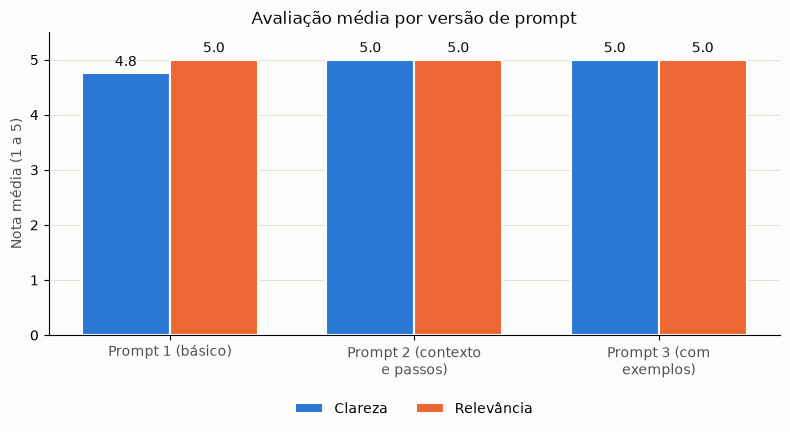

Gráfico guardado em grafico_comparacao_prompts_T4.png.


In [13]:
# Gráfico de barras com a clareza e a relevância médias de cada prompt
nomes_prompts = list(resumo_por_prompt.index)
posicoes_prompts = list(range(len(nomes_prompts)))
largura_barra = 0.36

figura_comparacao, eixo_comparacao = plt.subplots(figsize=(8, 4.5))
figura_comparacao.patch.set_facecolor("#fcfcfb")
eixo_comparacao.set_facecolor("#fcfcfb")

# Duas séries, com cores distintas (azul e laranja) e um pequeno espaço entre as barras
barras_clareza = eixo_comparacao.bar(
    [posicao - largura_barra / 2 for posicao in posicoes_prompts],
    resumo_por_prompt["clareza_media"],
    width=largura_barra, color="#2a78d6", edgecolor="#fcfcfb", linewidth=1.5, label="Clareza",
)
barras_relevancia = eixo_comparacao.bar(
    [posicao + largura_barra / 2 for posicao in posicoes_prompts],
    resumo_por_prompt["relevancia_media"],
    width=largura_barra, color="#eb6834", edgecolor="#fcfcfb", linewidth=1.5, label="Relevância",
)

# Escreve o valor no topo de cada barra
eixo_comparacao.bar_label(barras_clareza, fmt="%.1f", padding=3, color="#0b0b0b")
eixo_comparacao.bar_label(barras_relevancia, fmt="%.1f", padding=3, color="#0b0b0b")

# Eixos, título e grelha discreta
eixo_comparacao.set_xticks(posicoes_prompts)
eixo_comparacao.set_xticklabels([textwrap.fill(nome_prompt, 18) for nome_prompt in nomes_prompts], color="#52514e")
eixo_comparacao.set_ylim(0, 5.5)
eixo_comparacao.set_ylabel("Nota média (1 a 5)", color="#52514e")
eixo_comparacao.set_title("Avaliação média por versão de prompt", color="#0b0b0b")
eixo_comparacao.yaxis.grid(True, color="#e1e0d9", linewidth=0.8)
eixo_comparacao.set_axisbelow(True)
for lado_eixo in ("top", "right"):
    eixo_comparacao.spines[lado_eixo].set_visible(False)
# Legenda por baixo do gráfico, em linha, para não tapar as barras
eixo_comparacao.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)

plt.tight_layout()
figura_comparacao.savefig(ficheiro_grafico, dpi=200, facecolor=figura_comparacao.get_facecolor())
plt.show()
print(f"Gráfico guardado em {ficheiro_grafico}.")

### Resumo das operações

O registo de tentativas mostra quantas vezes foi preciso repetir pedidos e porquê. É o equivalente, nesta escala, à auditoria e ao *logging* descritos no excerto (secção 3.3).

In [14]:
# Passa o registo das tentativas para uma tabela e guarda-o em CSV (as colunas ficam definidas mesmo sem tentativas)
colunas_tentativas = ["data_hora", "modelo", "versao_prompt", "numero_pergunta", "numero_tentativa", "resultado", "codigo_erro", "tipo_erro", "tempo_segundos"]
tabela_tentativas = pd.DataFrame(registo_tentativas, columns=colunas_tentativas)
tabela_tentativas.to_csv(ficheiro_registo_tentativas, index=False, encoding="utf-8-sig")

# Separa as tentativas que falharam
tentativas_com_erro = tabela_tentativas[tabela_tentativas["resultado"] == "erro"]
tentativas_com_sucesso = tabela_tentativas[tabela_tentativas["resultado"] == "sucesso"]

print(f"Modelo(s) usado(s): {', '.join(sorted(tabela_tentativas['modelo'].unique()))}")
modelos_devolvidos = sorted(set(tabela_interacoes["modelo_devolvido"].dropna().astype(str)) - {""})
print(f"Modelo(s) indicado(s) pela API nas respostas: {', '.join(modelos_devolvidos) if modelos_devolvidos else 'não indicado'}")
print(f"Temperatura: {descricao_temperatura}")
print(f"Número total de tentativas (incluindo o teste inicial): {len(tabela_tentativas)}")
print(f"Tentativas com sucesso: {len(tentativas_com_sucesso)}")
print(f"Tentativas com erro: {len(tentativas_com_erro)}")

if len(tentativas_com_erro) > 0:
    print("Erros por código:")
    print(tentativas_com_erro["codigo_erro"].astype(str).value_counts().to_string())

print(f"Interações com resposta: {(tabela_interacoes['estado'] == 'sucesso').sum()} de {len(tabela_interacoes)}")

if len(tentativas_com_sucesso) > 0:
    print(f"Tempo médio de resposta (tentativas com sucesso): {tentativas_com_sucesso['tempo_segundos'].mean():.2f} segundos")
    print(f"Tempo mais longo de uma resposta: {tentativas_com_sucesso['tempo_segundos'].max():.2f} segundos")

Modelo(s) usado(s): gemini-3.5-flash
Modelo(s) indicado(s) pela API nas respostas: gemini-3.6-flash
Temperatura: por defeito do modelo
Número total de tentativas (incluindo o teste inicial): 14
Tentativas com sucesso: 14
Tentativas com erro: 0
Interações com resposta: 13 de 13
Tempo médio de resposta (tentativas com sucesso): 4.00 segundos
Tempo mais longo de uma resposta: 8.85 segundos


In [15]:
# Passo final de verificação: reabre os ficheiros gerados e mostra o que têm
registo_interacoes_guardado = pd.read_csv(ficheiro_registo_interacoes, encoding="utf-8-sig")
print(f"{ficheiro_registo_interacoes}: {len(registo_interacoes_guardado)} linhas")
print(registo_interacoes_guardado[["versao_prompt", "numero_pergunta", "estado", "tentativas", "tempo_resposta_segundos", "clareza", "relevancia"]].to_string(index=False))

registo_tentativas_guardado = pd.read_csv(ficheiro_registo_tentativas, encoding="utf-8-sig")
print(f"\n{ficheiro_registo_tentativas}: {len(registo_tentativas_guardado)} linhas")

with open(ficheiro_versoes_prompts, "r", encoding="utf-8") as ficheiro_aberto:
    versoes_guardadas = json.load(ficheiro_aberto)
print(f"{ficheiro_versoes_prompts}: {len(versoes_guardadas)} versões de prompts")

registo_interacoes_T4.csv: 13 linhas
               versao_prompt  numero_pergunta  estado  tentativas  tempo_resposta_segundos  clareza  relevancia
           Prompt 1 (básico)                1 sucesso           1                     2.40        4           5
           Prompt 1 (básico)                2 sucesso           1                     3.16        5           5
           Prompt 1 (básico)                3 sucesso           1                     4.46        5           5
           Prompt 1 (básico)                4 sucesso           1                     3.22        5           5
Prompt 2 (contexto e passos)                1 sucesso           1                     2.86        5           5
Prompt 2 (contexto e passos)                2 sucesso           1                     4.56        5           5
Prompt 2 (contexto e passos)                3 sucesso           1                     4.24        5           5
Prompt 2 (contexto e passos)                4 sucesso           1  

## Parte 4 (continuação): Melhorias propostas

- **Fidelidade ao excerto:** acrescentar um critério de avaliação que verifique se cada afirmação da resposta consta no texto. Na pergunta 3, o Prompt 1 incluiu detalhes que não estão no excerto («para os utilizadores», «uma tarefa específica») e a avaliação de relevância não os penalizou.
- **Mais dados e mais repetições:** mais perguntas e documentos (incluindo perguntas ambíguas ou com informação parcial) e várias repetições de cada pedido, para medir a variação entre execuções.
- **Avaliação:** complementar a avaliação manual com métricas automáticas (por exemplo, ROUGE) e com uma segunda pessoa a avaliar.
- **Consumo e quota:** registar o consumo de tokens de cada pedido (`usage_metadata`) e acompanhar a quota da conta.
- **Erros:** guardar a mensagem completa de cada erro e não repetir automaticamente um 429 de quota diária.
- **Versões dos prompts:** guardar o texto exato (ou um identificador, como um hash) do prompt em cada interação, com histórico.
- **Persistência:** carregar os CSV no arranque para retomar uma execução interrompida, e gravar o registo de tentativas a cada pedido.
- **Temperatura:** fazer um teste de sensibilidade, como exceção deliberada à recomendação da Google de manter o valor por defeito nos modelos Gemini 3, só para medir a variação das respostas.
- **Gráfico:** mostrar os valores das barras com duas casas decimais (`fmt="%.2f"`), para que 4,75 não apareça como 4,8.
